In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

In [2]:
# Load the Wine dataset
df = pd.read_csv("Wine dataset.csv")

# Display the first five rows
print(df.head())

   class  Alcohol  Malic acid   Ash  Alcalinity of ash  Magnesium  \
0      1    14.23        1.71  2.43               15.6        127   
1      1    13.20        1.78  2.14               11.2        100   
2      1    13.16        2.36  2.67               18.6        101   
3      1    14.37        1.95  2.50               16.8        113   
4      1    13.24        2.59  2.87               21.0        118   

   Total phenols  Flavanoids  Nonflavanoid phenols  Proanthocyanins  \
0           2.80        3.06                  0.28             2.29   
1           2.65        2.76                  0.26             1.28   
2           2.80        3.24                  0.30             2.81   
3           3.85        3.49                  0.24             2.18   
4           2.80        2.69                  0.39             1.82   

   Color intensity   Hue  OD280/OD315 of diluted wines  Proline   
0             5.64  1.04                          3.92      1065  
1             4.38  1.05

In [3]:
# Separate input features and class labels
X = df.drop(columns=["class"])
y = df["class"]

# Display the features and class labels
print("Features:")
print(X.head())

print("\nClass labels:")
print(y.head())

Features:
   Alcohol  Malic acid   Ash  Alcalinity of ash  Magnesium  Total phenols  \
0    14.23        1.71  2.43               15.6        127           2.80   
1    13.20        1.78  2.14               11.2        100           2.65   
2    13.16        2.36  2.67               18.6        101           2.80   
3    14.37        1.95  2.50               16.8        113           3.85   
4    13.24        2.59  2.87               21.0        118           2.80   

   Flavanoids  Nonflavanoid phenols  Proanthocyanins  Color intensity   Hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   OD280/OD315 of diluted wines  Proline   
0       

In [4]:
# Create a StandardScaler object
scaler = StandardScaler()

# Standardize the features
X_scaled = scaler.fit_transform(X)

# Display the first five standardized rows
print(X_scaled[:5])

[[ 1.51861254 -0.5622498   0.23205254 -1.16959318  1.91390522  0.80899739
   1.03481896 -0.65956311  1.22488398  0.25171685  0.36217728  1.84791957
   1.01300893]
 [ 0.24628963 -0.49941338 -0.82799632 -2.49084714  0.01814502  0.56864766
   0.73362894 -0.82071924 -0.54472099 -0.29332133  0.40605066  1.1134493
   0.96524152]
 [ 0.19687903  0.02123125  1.10933436 -0.2687382   0.08835836  0.80899739
   1.21553297 -0.49840699  2.13596773  0.26901965  0.31830389  0.78858745
   1.39514818]
 [ 1.69154964 -0.34681064  0.4879264  -0.80925118  0.93091845  2.49144552
   1.46652465 -0.98187536  1.03215473  1.18606801 -0.42754369  1.18407144
   2.33457383]
 [ 0.29570023  0.22769377  1.84040254  0.45194578  1.28198515  0.80899739
   0.66335127  0.22679555  0.40140444 -0.31927553  0.36217728  0.44960118
  -0.03787401]]


In [5]:
# Store inertia values
inertia_values = []

# Run K-Means for different K values
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)

    inertia_values.append(model.inertia_)

# Display inertia values
print(inertia_values)

[2313.9999999999986, 1658.7588524290961, 1277.928488844643, 1175.4283331033473, 1109.5127392938246, 1046.002333214364, 981.5952326111659, 935.201211473855, 889.8929111933173, 845.8952366525514]


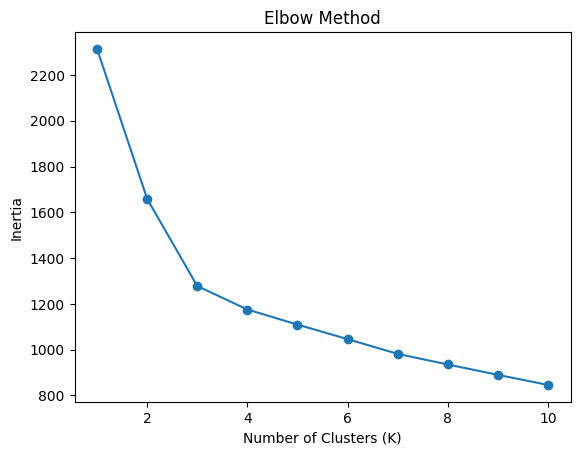

In [6]:
# Plot K against inertia
plt.plot(range(1, 11), inertia_values, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [7]:
# Create the final K-Means model
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Train the model
kmeans.fit(X_scaled)

print("K-Means model trained successfully.")

K-Means model trained successfully.


In [8]:
# Get cluster labels for each data point
labels = kmeans.labels_

# Get the cluster centroids
centroids = kmeans.cluster_centers_

print("Cluster labels:")
print(labels)

print("\nCluster centroids:")
print(centroids)

Cluster labels:
[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 0 1 0 0 0 0 0 0 0 0 0 0 0 2
 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 1 0 0 2 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]

Cluster centroids:
[[-0.92607185 -0.39404154 -0.49451676  0.17060184 -0.49171185 -0.07598265
   0.02081257 -0.03353357  0.0582655  -0.90191402  0.46180361  0.27076419
  -0.75384618]
 [ 0.16490746  0.87154706  0.18689833  0.52436746 -0.07547277 -0.97933029
  -1.21524764  0.72606354 -0.77970639  0.94153874 -1.16478865 -1.29241163
  -0.40708796]
 [ 0.83523208 -0.30380968  0.36470604 -0.61019129  0.5775868   0.88523736
   0.97781956 -0.56208965  0.58028658  0.17106348  0.47398365  0.77924711
   1.12518529]]


In [9]:
# Create a PCA object with 2 components
pca = PCA(n_components=2)

# Reduce the standardized features to 2 dimensions
X_pca = pca.fit_transform(X_scaled)

# Display the first five reduced rows
print(X_pca[:5])

[[ 3.31675081  1.44346263]
 [ 2.20946492 -0.33339289]
 [ 2.51674015  1.0311513 ]
 [ 3.75706561  2.75637191]
 [ 1.00890849  0.86983082]]


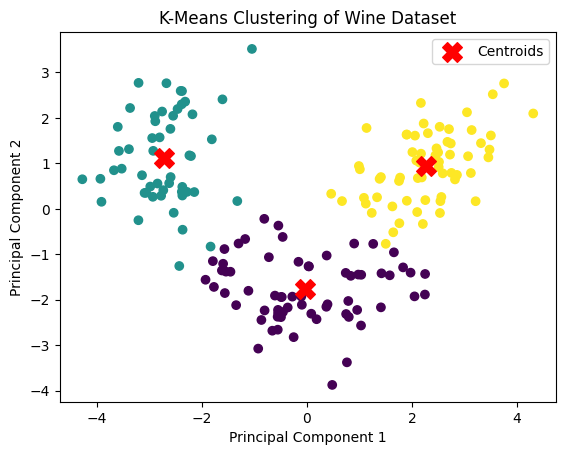

In [10]:
# Transform cluster centroids into 2D using PCA
centroids_pca = pca.transform(centroids)

# Plot the clusters
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap="viridis")

# Plot the centroids
plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    marker="X",
    s=200,
    color="red",
    label="Centroids"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering of Wine Dataset")
plt.legend()
plt.show()

In [11]:
from sklearn.metrics import silhouette_score

# Calculate the silhouette score
score = silhouette_score(X_scaled, labels)

print("Inertia:", kmeans.inertia_)
print("Silhouette Score:", score)

Inertia: 1277.928488844643
Silhouette Score: 0.2848589191898987


In [12]:
# Create a comparison table
comparison = pd.DataFrame({
    "Original Class": y,
    "Cluster": labels
})

# Display the comparison
print(comparison.head(10))

print("\nClass and Cluster Comparison:")
print(pd.crosstab(comparison["Original Class"],
                  comparison["Cluster"]))

   Original Class  Cluster
0               1        2
1               1        2
2               1        2
3               1        2
4               1        2
5               1        2
6               1        2
7               1        2
8               1        2
9               1        2

Class and Cluster Comparison:
Cluster          0   1   2
Original Class            
1                0   0  59
2               65   3   3
3                0  48   0
